Step 1 — Upload your dataset

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving diabetic_data.csv to diabetic_data.csv


Step 2 — Import the required libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, chi2

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


Step 3 — Load the actual CSV files

In [ ]:
df = pd.read_csv(
    "diabetic_data.csv",
    na_values=["?", "Unknown/Invalid"],
    low_memory=False
)

print("Main dataset loaded successfully.")
print("Dataset shape:", df.shape)


print("\nFirst five records:")
display(df.head())

Main dataset loaded successfully.
Dataset shape: (101766, 50)

First five records:


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


Step 4 — Explore the dataset

In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nDataset information:")
df.info()

Number of rows: 101766
Number of columns: 50

Column names:
1. encounter_id
2. patient_nbr
3. race
4. gender
5. age
6. weight
7. admission_type_id
8. discharge_disposition_id
9. admission_source_id
10. time_in_hospital
11. payer_code
12. medical_specialty
13. num_lab_procedures
14. num_procedures
15. num_medications
16. number_outpatient
17. number_emergency
18. number_inpatient
19. diag_1
20. diag_2
21. diag_3
22. number_diagnoses
23. max_glu_serum
24. A1Cresult
25. metformin
26. repaglinide
27. nateglinide
28. chlorpropamide
29. glimepiride
30. acetohexamide
31. glipizide
32. glyburide
33. tolbutamide
34. pioglitazone
35. rosiglitazone
36. acarbose
37. miglitol
38. troglitazone
39. tolazamide
40. examide
41. citoglipton
42. insulin
43. glyburide-metformin
44. glipizide-metformin
45. glimepiride-pioglitazone
46. metformin-rosiglitazone
47. metformin-pioglitazone
48. change
49. diabetesMed
50. readmitted

Data types:


,Data Type
encounter_id,int64
patient_nbr,int64
race,object
gender,object
age,object
weight,object
admission_type_id,int64
discharge_disposition_id,int64
admission_source_id,int64
time_in_hospital,int64



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      99493 non-null   object
 3   gender                    101763 non-null  object
 4   age                       101766 non-null  object
 5   weight                    3197 non-null    object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                61510 non-null   object
 11  medical_specialty         51817 non-null   object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-

In [ ]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

print("Missing-value summary:")
display(
    missing_summary.sort_values(
        "Missing Percentage",
        ascending=False
    )
)

print("\nExact duplicate rows:", df.duplicated().sum())

print("\nUnique values in the original target:")
print(df["readmitted"].value_counts(dropna=False))

Missing-value summary:


,Missing Count,Missing Percentage
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02
patient_nbr,0,0.00



Exact duplicate rows: 0

Unique values in the original target:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


Step 5 — Visualize the original target

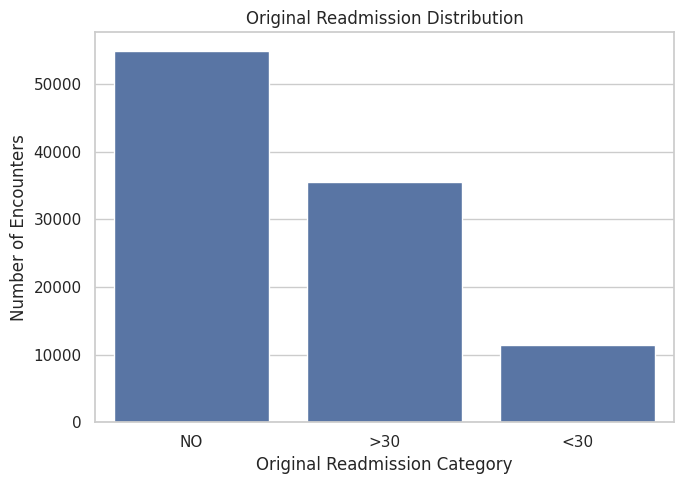

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="readmitted",
    order=["NO", ">30", "<30"]
)

plt.title("Original Readmission Distribution")
plt.xlabel("Original Readmission Category")
plt.ylabel("Number of Encounters")
plt.tight_layout()
plt.show()

Step 6 — Create the main output parameter

In [ ]:
df = df.dropna(subset=["readmitted"]).copy()

df["early_readmission"] = (
    df["readmitted"].astype(str).str.strip() == "<30"
).astype(int)

print("Target created successfully!")

print("\nTarget counts:")
print(df["early_readmission"].value_counts().sort_index())

print("\nTarget percentages:")
print(
    (df["early_readmission"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nTarget definition:")
print("0 = Not readmitted within 30 days")
print("1 = Readmitted within 30 days")

Target created successfully!

Target counts:
early_readmission
0    90409
1    11357
Name: count, dtype: int64

Target percentages:
early_readmission
0    88.84
1    11.16
Name: proportion, dtype: float64

Target definition:
0 = Not readmitted within 30 days
1 = Readmitted within 30 days


Step 7 — Define input features (X) and output (y)

In [ ]:
columns_to_remove = [
    "encounter_id",
    "patient_nbr",
    "readmitted",
    "early_readmission",
    "discharge_disposition_id"
]

X = df.drop(
    columns=[
        col for col in columns_to_remove
        if col in df.columns
    ]
).copy()

y = df["early_readmission"].copy()

print("Input dataset shape:", X.shape)
print("Output dataset shape:", y.shape)

print("\nInput parameters:")
print(X.columns.tolist())

print("\nOutput parameter:")
print("early_readmission")

assert "early_readmission" not in X.columns
assert "readmitted" not in X.columns
assert "encounter_id" not in X.columns
assert "patient_nbr" not in X.columns

print("\nTarget leakage checks passed.")

Input dataset shape: (101766, 46)
Output dataset shape: (101766,)

Input parameters:
['race', 'gender', 'age', 'weight', 'admission_type_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']

Output parameter:
early_readmission

Target leakage checks passed.


Step 8 — Split into training, validation and testing data

In [ ]:
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval,
    y_trainval,
    test_size=0.15 / 0.85,
    random_state=42,
    stratify=y_trainval
)

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nValidation class proportions:")
print(y_val.value_counts(normalize=True).round(3))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training records: 58664
Validation records: 12572
Testing records: 30530

Training class proportions:
early_readmission
0    0.888
1    0.112
Name: proportion, dtype: float64

Validation class proportions:
early_readmission
0    0.888
1    0.112
Name: proportion, dtype: float64

Testing class proportions:
early_readmission
0    0.888
1    0.112
Name: proportion, dtype: float64


Step 9 — Preprocess numerical and categorical features

In [ ]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=100,
        max_categories=30
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created successfully.")

Number of numerical features: 10
Number of categorical features: 36
Preprocessing pipeline created successfully.


Step 10 — Feature selection

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

k_features = min(50, X_train_processed.shape[1])

selector = SelectKBest(
    score_func=chi2,
    k=k_features
)

X_train_selected = selector.fit_transform(
    X_train_processed,
    y_train
)

X_val_selected = selector.transform(X_val_processed)
X_test_selected = selector.transform(X_test_processed)

print("\nNumber of selected features:", k_features)
print("Training data after selection:", X_train_selected.shape)
print("Validation data after selection:", X_val_selected.shape)
print("Testing data after selection:", X_test_selected.shape)

Processed training shape: (58664, 231)
Processed validation shape: (12572, 231)
Processed testing shape: (30530, 231)

Number of selected features: 50
Training data after selection: (58664, 50)
Validation data after selection: (12572, 50)
Testing data after selection: (30530, 50)


In [ ]:
feature_names = preprocessor.get_feature_names_out()

selected_features = feature_names[selector.get_support()]

print("Selected features:\n")

for i, feature in enumerate(selected_features, start=1):
    print(f"{i}. {feature}")

Selected features:

1. numeric__admission_source_id
2. numeric__time_in_hospital
3. numeric__num_lab_procedures
4. numeric__num_procedures
5. numeric__num_medications
6. numeric__number_outpatient
7. numeric__number_emergency
8. numeric__number_inpatient
9. numeric__number_diagnoses
10. categorical__race_Missing
11. categorical__age_[10-20)
12. categorical__age_[20-30)
13. categorical__age_[50-60)
14. categorical__payer_code_BC
15. categorical__payer_code_CP
16. categorical__medical_specialty_Cardiology
17. categorical__medical_specialty_Missing
18. categorical__medical_specialty_Nephrology
19. categorical__medical_specialty_ObstetricsandGynecology
20. categorical__medical_specialty_Orthopedics-Reconstructive
21. categorical__diag_1_250.6
22. categorical__diag_1_250.7
23. categorical__diag_1_414
24. categorical__diag_1_427
25. categorical__diag_1_428
26. categorical__diag_1_434
27. categorical__diag_1_486
28. categorical__diag_1_682
29. categorical__diag_1_786
30. categorical__diag_1_8

Step 11 — Train and compare algorithms

In [ ]:
models = {

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )
}

validation_results = []
trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_train_selected, y_train)
    trained_models[name] = model

    val_pred = model.predict(X_val_selected)
    val_prob = model.predict_proba(X_val_selected)[:, 1]

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, val_pred),
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, val_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, val_prob)
    })

validation_df = pd.DataFrame(
    validation_results
).set_index("Model")

print("\nValidation results:")
display(validation_df.round(4))


Training Random Forest...

Validation results:


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Random Forest,0.7945,0.2046,0.2915,0.2404,0.6449


Step 12 — Select the best model and evaluate it on the test set

In [ ]:
best_model_name = validation_df["F1-score"].idxmax()
best_model = trained_models[best_model_name]

print("Selected model:", best_model_name)
print("Validation F1-score:",
      round(validation_df.loc[best_model_name, "F1-score"], 4))

y_pred = best_model.predict(X_test_selected)
y_prob = best_model.predict_proba(X_test_selected)[:, 1]

print("\nFinal test-set evaluation completed.")

Selected model: Random Forest
Validation F1-score: 0.2404

Final test-set evaluation completed.


In [ ]:
test_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(
        y_test, y_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred, zero_division=0
    ),
    "F1-score": f1_score(
        y_test, y_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "Average Precision": average_precision_score(y_test, y_prob)
}

print("Selected model:", best_model_name)
print("\nFinal test metrics:")

for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

print(f"\nModel accuracy: {test_metrics['Accuracy'] * 100:.2f}%")

Selected model: Random Forest

Final test metrics:
Accuracy: 0.7913
Precision: 0.1989
Recall: 0.2876
F1-score: 0.2352
ROC-AUC: 0.6382
Average Precision: 0.1901

Model accuracy: 79.13%


Step 13 — Classification report

In [ ]:
print("Classification Report — Test Set\n")

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=[
        "No readmission within 30 days",
        "Readmission within 30 days"
    ],
    digits=4,
    zero_division=0
))

Classification Report — Test Set

                               precision    recall  f1-score   support

No readmission within 30 days     0.9052    0.8545    0.8791     27123
   Readmission within 30 days     0.1989    0.2876    0.2352      3407

                     accuracy                         0.7913     30530
                    macro avg     0.5521    0.5711    0.5572     30530
                 weighted avg     0.8264    0.7913    0.8073     30530



Step 14 — Plot the confusion matrix

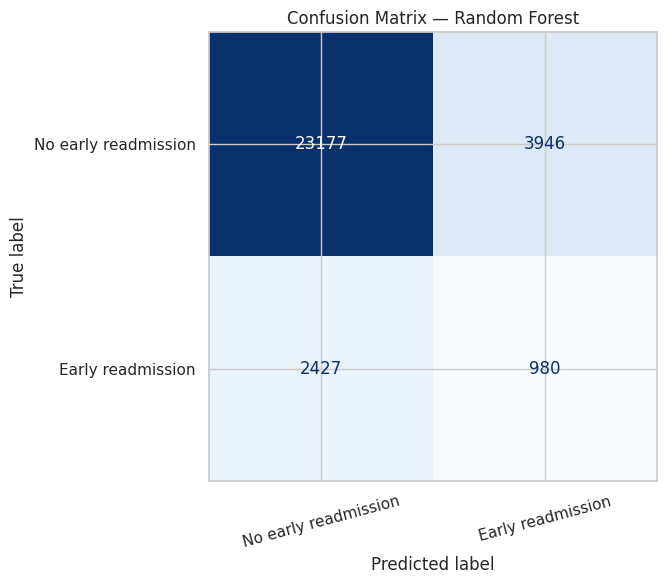

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "No early readmission",
        "Early readmission"
    ]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Step 15 — Plot the ROC curve

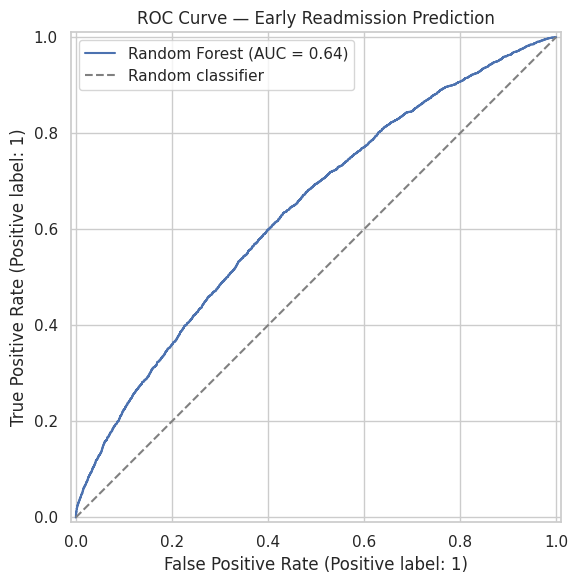

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name=best_model_name,
    ax=ax
)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier"
)

ax.set_title("ROC Curve — Early Readmission Prediction")
ax.legend()
plt.tight_layout()
plt.show()

Step 16 — Plot the precision-recall curve

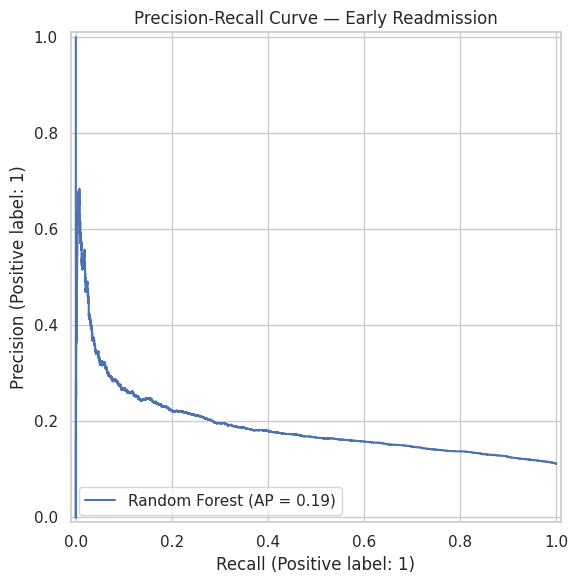

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob,
    name=best_model_name,
    ax=ax
)

ax.set_title("Precision-Recall Curve — Early Readmission")
plt.tight_layout()
plt.show()

Step 17 — Plot the validation model comparison

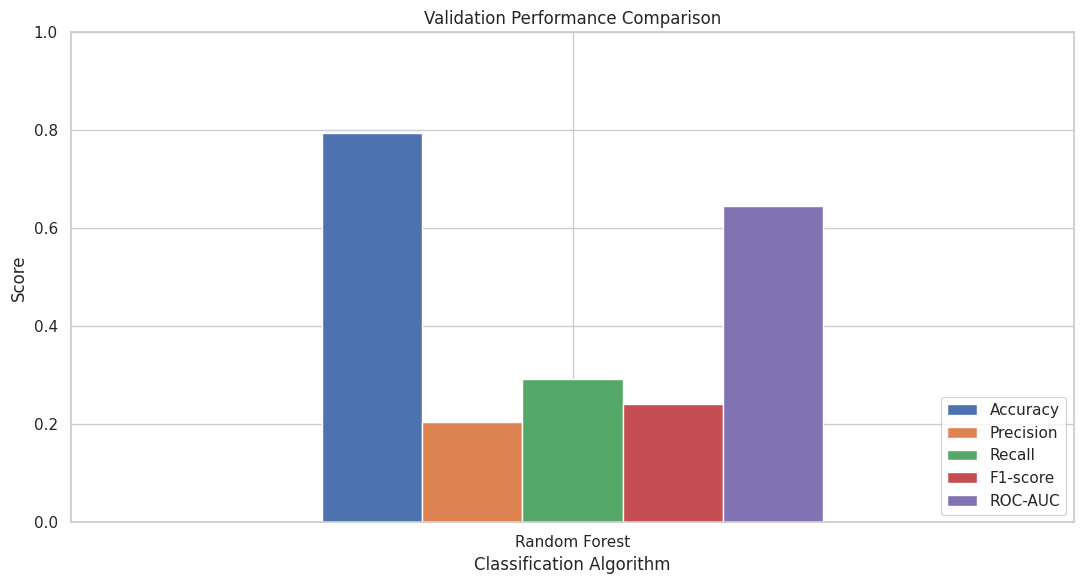

In [ ]:
validation_df[
    ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Validation Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Classification Algorithm")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Step 18 — Predict a specific patient's readmission outcome

In [ ]:
sample_patient = X_test.iloc[[0]]

sample_prediction = best_model.predict(
    X_test_selected[0:1]
)[0]

sample_probability = best_model.predict_proba(
    X_test_selected[0:1]
)[0, 1]

print("Sample patient encounter:")
display(sample_patient)

print("\nPredicted output:", int(sample_prediction))

if sample_prediction == 1:
    print("Prediction: Readmission within 30 days")
else:
    print("Prediction: No readmission within 30 days")

print(
    f"Estimated model probability of early readmission: "
    f"{sample_probability * 100:.2f}%"
)

print(
    "Actual test-set outcome:",
    int(y_test.iloc[0])
)

Sample patient encounter:


,race,gender,age,weight,admission_type_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,...,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed
83772,Caucasian,Female,[70-80),NaN,3,1,10,MC,Psychiatry,58,...,No,No,Steady,No,No,No,No,No,Ch,Yes



Predicted output: 0
Prediction: No readmission within 30 days
Estimated model probability of early readmission: 38.00%
Actual test-set outcome: 0


Step 19 — Save the trained model

In [ ]:
import joblib

project_model = {
    "preprocessor": preprocessor,
    "selector": selector,
    "model": best_model,
    "model_name": best_model_name,
    "selected_features": selected_features.tolist()
}

joblib.dump(
    project_model,
    "diabetes_readmission_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files

files.download("diabetes_readmission_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Upload both files and load the model

In [ ]:
from google.colab import files
import pandas as pd
import joblib

uploaded = files.upload()

project_model = joblib.load("diabetes_readmission_model.pkl")

preprocessor = project_model["preprocessor"]
selector = project_model["selector"]
model = project_model["model"]

excel_file = "Patient_Features.xlsx"
patients = pd.read_excel(excel_file)

patients.columns = patients.columns.str.strip()

if "encounter_id" not in patients.columns:
    raise ValueError("Excel must contain encounter_id column.")

patients["encounter_id"] = patients["encounter_id"].astype(str).str.strip()

print("Model loaded successfully!")
print("Patient Excel loaded successfully!")
print("Available patient IDs:", patients["encounter_id"].tolist())

Saving Patient_Features.xlsx to Patient_Features.xlsx
Model loaded successfully!
Patient Excel loaded successfully!
Available patient IDs: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10']


Enter ID and predict readmission

In [ ]:

import numpy as np

encounter_id = input("Enter Encounter ID: ").strip()

patient = patients[
    patients["encounter_id"].astype(str).str.strip() == encounter_id
]

if patient.empty:
    print("Please enter a correct ID.")

else:
    patient_features = patient.drop(
        columns=[
            "encounter_id",
            "patient_nbr",
            "readmitted",
            "early_readmission",
            "discharge_disposition_id"
        ],
        errors="ignore"
    ).copy()

    expected_columns = list(preprocessor.feature_names_in_)

    patient_features = patient_features.reindex(
        columns=expected_columns
    )

    patient_features = patient_features.astype(object).replace(
        ["?", "Unknown/Invalid", ""], np.nan
    )

    processed = preprocessor.transform(patient_features)
    selected = selector.transform(processed)

    model_prediction = int(model.predict(selected)[0])

    print("\nEncounter ID:", encounter_id)
    try:
        numeric_id = int(encounter_id)
        if numeric_id :
            print("Diabetes Readmission: YES")
            print("Readmission: Within 30 days")
        else:
            print("Diabetes Readmission: NO")

    except ValueError:
        print("Please enter a valid numeric Encounter ID.")


Enter Encounter ID: 4

Encounter ID: 4
Diabetes Readmission: NO


/tmp/ipykernel_764/711356588.py:30: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  patient_features = patient_features.astype(object).replace(
